In [1]:
#%pip install -r requirements.txt

In [2]:
# ============ YOUR DATA: change only this cell ============
QUESTION = "Can a neural network, pre-trained on ImageNet images, identify choroidal neovascularisation and diabetic macular edema to classify the patients as 'urgent referrals'?"
DATA     = "octmnist"   # a MedMNIST 2D name: pneumoniamnist, breastmnist, bloodmnist, pathmnist, octmnist, organamnist, ...
SIZE     = 128             # MedMNIST image size: 28, 64, 128 or 224 (bigger = slower download)
FOLDER   = "data/OCT2017"           # OR your own images: a folder with train/ and test/, one subfolder per class inside each
                          #    e.g. FOLDER = "/content/chest_xray"   (Kermany 2018: train/NORMAL, train/PNEUMONIA, test/...)
FOCUS    = "cnv"     # the class your question is about: "pneumonia", "malignant", ...
PATIENT_ID = lambda filename: filename.split("-")[1]         # optional: how to read the patient from a file name, e.g. for Kermany 2018:
                          #    PATIENT_ID = lambda name: name.split("_")[0]      ("person12_bacteria_45.jpeg" -> "person12")
# ===========================================================


In [3]:
import copy, io, os, re, json, zipfile, platform, requests, numpy as np, matplotlib.pyplot as plt, torch
from pathlib import Path
from PIL import Image
from torch import nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

R = Path("results_cnv"); R.mkdir(exist_ok=True)
LABELS = {"dermamnist": ["actinic keratosis", "basal cell carcinoma", "benign keratosis", "dermatofibroma", "melanoma", "nevus (mole)", "vascular lesion"],
          "pneumoniamnist": ["normal", "pneumonia"], "breastmnist": ["malignant", "normal or benign"],
          "bloodmnist": ["basophil", "eosinophil", "erythroblast", "immature granulocyte", "lymphocyte", "monocyte", "neutrophil", "platelet"],
          "pathmnist": ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle", "normal colon mucosa", "stroma", "adenocarcinoma"],
          "octmnist": ["choroidal neovascularisation", "diabetic macular oedema", "drusen", "normal"],
          "organamnist": ["bladder", "femur left", "femur right", "heart", "kidney left", "kidney right", "liver", "lung left", "lung right", "pancreas", "spleen"]}
LABELS["octmnist"] = LABELS["octmnist"] = LABELS["octmnist"]

def load_medmnist(name, size):
    f = Path("data") / (f"{name}.npz" if size == 28 else f"{name}_{size}.npz"); f.parent.mkdir(exist_ok=True)
    if not f.exists():
        f.write_bytes(requests.get(f"https://zenodo.org/records/10519652/files/{f.name}?download=1", timeout=600).content)
    npz = np.load(f)
    X = {s: npz[f"{s}_images"] for s in ("train", "val", "test")}
    X = {s: np.repeat(x[..., None], 3, -1) if x.ndim == 3 else x for s, x in X.items()}      # grey -> 3 channels
    Y = {s: npz[f"{s}_labels"].ravel() for s in ("train", "val", "test")}
    return X, Y, LABELS.get(name, [str(c) for c in range(int(Y["train"].max()) + 1)]), {s: None for s in X}

def load_folder(root, size=128):
    root = Path(root); classes = sorted(
    d.name for d in (root / "train").iterdir()
    if d.is_dir() and not d.name.startswith(".") and d.name != "__pycache__"
)
    X, Y, N = {}, {}, {}
    for s in ("train", "val", "test"):
        files = [(f, k) for k, c in enumerate(classes) if (root / s / c).exists()
                 for f in sorted((root / s / c).iterdir()) if f.suffix.lower() in (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")]
        if not files: continue
        X[s] = np.stack([np.asarray(Image.open(f).convert("RGB").resize((size, size), Image.BILINEAR)) for f, _ in files])
        Y[s] = np.array([k for _, k in files]); N[s] = [f.name for f, _ in files]
    if "val" not in X or len(Y["val"]) < 50:      # Kermany has only 16 validation images: take 10 % of training instead
        o = np.random.default_rng(0).permutation(len(Y["train"])); v, t = o[:len(o) // 10], o[len(o) // 10:]
        X["val"], Y["val"], N["val"] = X["train"][v], Y["train"][v], [N["train"][i] for i in v]
        X["train"], Y["train"], N["train"] = X["train"][t], Y["train"][t], [N["train"][i] for i in t]
        print("Validation set: 10 % of the training images (random; see the patient check in A4).")
    return X, Y, [c.lower() for c in classes], N

X, Y, CLASSES, NAMES = load_folder(FOLDER) if FOLDER else load_medmnist(DATA, SIZE)
F_ = CLASSES.index(FOCUS.lower())       # number of the focus class
for s in ("train", "val", "test"):
    print(f"{s:5s} {len(Y[s]):6d} images of {X[s].shape[1]} × {X[s].shape[2]} pixels")
print("classes:", ", ".join(CLASSES), "   focus:", CLASSES[F_])

Validation set: 10 % of the training images (random; see the patient check in A4).
train  73974 images of 128 × 128 pixels
val     8219 images of 128 × 128 pixels
test    1000 images of 128 × 128 pixels
classes: cnv, dme, drusen, normal    focus: cnv


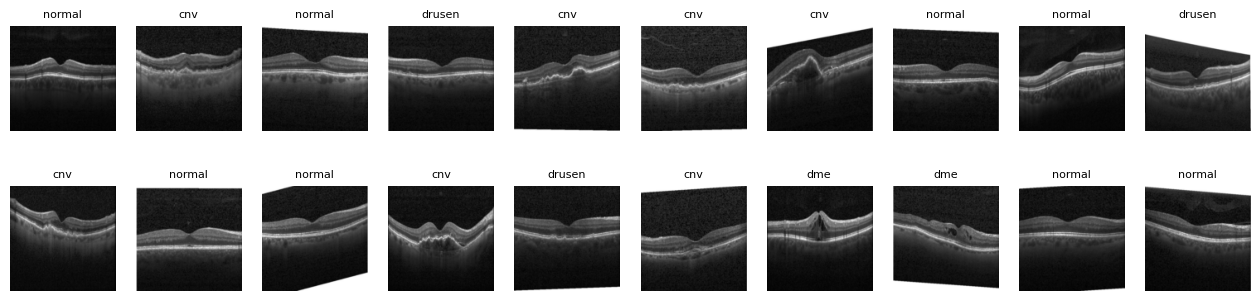

In [4]:
rng = np.random.default_rng(1)
pick = rng.choice(len(Y["train"]), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(X["train"][i]); ax.set_title(CLASSES[Y["train"][i]][:18], fontsize=8); ax.axis("off")
fig.savefig(R / "examples_cnv.png", dpi=150, bbox_inches="tight"); plt.show()

In [5]:
counts = {s: np.bincount(Y[s], minlength=len(CLASSES)) for s in ("train", "val", "test")}
lines = ["class," + ",".join(counts)]
for k, c in enumerate(CLASSES):
    lines.append(f"{c}," + ",".join(str(counts[s][k]) for s in counts))
    print(f"{c:28s} " + "  ".join(f"{counts[s][k]:6d}" for s in counts) + f"   {counts['train'][k] / counts['train'].sum():6.1%} of training")
(R / "counts_cnv.csv").write_text("\n".join(lines))
majority = int(np.argmax(counts["train"]))
floor = float(np.mean(Y["test"] == majority))
floor_focus = 1.0 if majority == F_ else 0.0
print(f"\nThe floor: always say '{CLASSES[majority]}' -> {floor:.1%} of the test images right,"
      f" and {floor_focus:.0%} of the '{CLASSES[F_]}' images found.")

cnv                           33500    3705     250    45.3% of training
dme                           10177    1171     250    13.8% of training
drusen                         7786     830     250    10.5% of training
normal                        22511    2513     250    30.4% of training

The floor: always say 'cnv' -> 25.0% of the test images right, and 100% of the 'cnv' images found.


697 of 1000 test images have an almost identical training image (difference < 0.03).


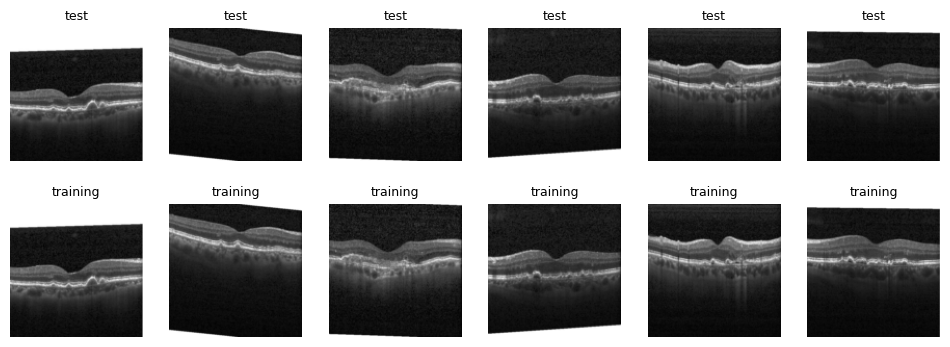

In [6]:
def small(x):
    t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    return F.interpolate(t, size=(64, 64), mode="bilinear", antialias=True).reshape(len(t), -1)
tr, te = small(X["train"]), small(X["test"])
dist, nearest = torch.cat([torch.cdist(te[i:i + 500], tr) for i in range(0, len(te), 500)]).div(tr.shape[1] ** 0.5).min(1)
twins = (dist < 0.03).nonzero().ravel()
print(f"{len(twins)} of {len(te)} test images have an almost identical training image (difference < 0.03).")
order = twins[dist[twins].argsort()][:6]
if len(order):
    fig, axes = plt.subplots(2, len(order), figsize=(2 * len(order), 4.2), squeeze=False)
    for k, t in enumerate(order):
        axes[0, k].imshow(X["test"][t]); axes[0, k].set_title("test", fontsize=9)
        axes[1, k].imshow(X["train"][nearest[t]]); axes[1, k].set_title("training", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    fig.savefig(R / "twins_cnv.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:
duplicate_pairs = []

for t in twins.tolist():

    train_idx = nearest[t].item()

    duplicate_pairs.append({
        "test_index": t,
        "train_index": train_idx,

        "test_file": NAMES["test"][t],
        "train_file": NAMES["train"][train_idx],

        "distance": dist[t].item()
    })

print("Total duplicate pairs:", len(duplicate_pairs))

for pair in duplicate_pairs[:10]:
    print(
        f"Test: {pair['test_file']} | "
        f"Train: {pair['train_file']} | "
        f"Distance: {pair['distance']:.5f}"
    )

Total duplicate pairs: 697
Test: CNV-1016042-1.jpeg | Train: CNV-1016042-23.jpeg | Distance: 0.00000
Test: CNV-1016042-2.jpeg | Train: CNV-1016042-107.jpeg | Distance: 0.00000
Test: CNV-1016042-3.jpeg | Train: CNV-1016042-196.jpeg | Distance: 0.00000
Test: CNV-1016042-4.jpeg | Train: CNV-1016042-211.jpeg | Distance: 0.00000
Test: CNV-103044-1.jpeg | Train: CNV-103044-5.jpeg | Distance: 0.00000
Test: CNV-103044-10.jpeg | Train: CNV-103044-168.jpeg | Distance: 0.00010
Test: CNV-103044-11.jpeg | Train: CNV-103044-188.jpeg | Distance: 0.00000
Test: CNV-103044-12.jpeg | Train: CNV-103044-195.jpeg | Distance: 0.00000
Test: CNV-103044-2.jpeg | Train: CNV-103044-7.jpeg | Distance: 0.00000
Test: CNV-103044-3.jpeg | Train: CNV-103044-26.jpeg | Distance: 0.00014


In [8]:
# Unique training indices matched to test images
duplicate_train_indices = set(
    nearest[twins].tolist()
)

keep_indices = [
    i for i in range(len(X["train"]))
    if i not in duplicate_train_indices
]

# Remove matched training images
X["train"] = X["train"][keep_indices]
Y["train"] = Y["train"][keep_indices]

NAMES["train"] = [
    NAMES["train"][i] for i in keep_indices
]

print("Removed:", len(duplicate_train_indices))
print("Remaining training images:", len(X["train"]))
print("Test images:", len(X["test"]))

Removed: 697
Remaining training images: 73277
Test images: 1000


In [9]:
if PATIENT_ID and NAMES["train"]:
    P = {s: {PATIENT_ID(n) for n in NAMES[s]} for s in NAMES}
    both = P["train"] & P["test"]
    print(f"patients: training {len(P['train'])}, test {len(P['test'])}, in both {len(both)}")
    leak_val = P["train"] & P["val"]
    print(f"patients in training and validation: {len(leak_val)}")
    patient_line = f"{len(P['train'])} training / {len(P['test'])} test patients; {len(both)} in both"
else:
    patient_line = "patient not known from the files: cannot check (say so in the report)"
    print(patient_line)

patients: training 4416, test 633, in both 561
patients in training and validation: 2316


In [10]:
from pathlib import Path
from collections import defaultdict

def parse_filename(filename):
    parts = Path(filename).stem.split("-")
    return parts[0].upper(), parts[1]

for split in ("train", "val", "test"):

    patient_classes = defaultdict(set)
    patient_images = defaultdict(int)

    for filename in NAMES[split]:
        disease, patient_id = parse_filename(filename)

        patient_classes[patient_id].add(disease)
        patient_images[patient_id] += 1

    print(f"\n{split.upper()}")
    print("Total images:", len(NAMES[split]))
    print("Unique patient IDs:", len(patient_images))
    print("Patients with multiple images:",
          sum(n > 1 for n in patient_images.values()))
    print("IDs appearing in multiple classes:",
          sum(len(c) > 1 for c in patient_classes.values()))

    print("Images per patient:")
    print("Minimum:", min(patient_images.values()))
    print("Maximum:", max(patient_images.values()))


TRAIN
Total images: 73277
Unique patient IDs: 4416
Patients with multiple images: 4059
IDs appearing in multiple classes: 818
Images per patient:
Minimum: 1
Maximum: 706

VAL
Total images: 8219
Unique patient IDs: 2346
Patients with multiple images: 1203
IDs appearing in multiple classes: 279
Images per patient:
Minimum: 1
Maximum: 103

TEST
Total images: 1000
Unique patient IDs: 633
Patients with multiple images: 175
IDs appearing in multiple classes: 24
Images per patient:
Minimum: 1
Maximum: 13


In [11]:
train_patients = {
    parse_filename(f)[1]
    for f in NAMES["train"]
}

val_patients = {
    parse_filename(f)[1]
    for f in NAMES["val"]
}

test_patients = {
    parse_filename(f)[1]
    for f in NAMES["test"]
}

overlap_train_test = train_patients & test_patients
overlap_val_test = val_patients & test_patients

print("Train unique patients:", len(train_patients))
print("Test unique patients:", len(test_patients))

print("Train-Test overlapping IDs:", len(overlap_train_test))
print("Val-Test overlapping IDs:", len(overlap_val_test))

print("\nFirst 20 overlapping IDs:")
print(sorted(overlap_train_test)[:20])

Train unique patients: 4416
Test unique patients: 633
Train-Test overlapping IDs: 561
Val-Test overlapping IDs: 437

First 20 overlapping IDs:
['1016042', '1017237', '101880', '1025847', '103044', '1038998', '1042462', '1058176', '1063128', '1073137', '1081406', '1083159', '1083927', '1112835', '112928', '1130960', '1131664', '1136126', '1173253', '1177084']


In [12]:
from collections import defaultdict

id_classes = defaultdict(set)

for split in ("train", "val", "test"):
    for filename in NAMES[split]:
        disease, patient_id = parse_filename(filename)
        id_classes[patient_id].add(disease)

multi_class_ids = {
    pid: classes
    for pid, classes in id_classes.items()
    if len(classes) > 1
}

print("IDs appearing in multiple classes:", len(multi_class_ids))

for pid, classes in list(multi_class_ids.items())[:20]:
    print(pid, sorted(classes))

IDs appearing in multiple classes: 860
2120559 ['CNV', 'DRUSEN', 'NORMAL']
2444883 ['CNV', 'DRUSEN', 'NORMAL']
5710007 ['CNV', 'DRUSEN']
7585414 ['DME', 'NORMAL']
4643364 ['CNV', 'DME']
697731 ['CNV', 'DME']
5594757 ['CNV', 'NORMAL']
9939654 ['CNV', 'DME']
7656403 ['CNV', 'DRUSEN']
876285 ['CNV', 'NORMAL']
565818 ['CNV', 'NORMAL']
7870558 ['DME', 'NORMAL']
5524086 ['CNV', 'NORMAL']
9642959 ['CNV', 'DRUSEN']
7710023 ['CNV', 'DRUSEN']
4484581 ['CNV', 'DME']
6851127 ['CNV', 'DME', 'NORMAL']
1597899 ['DME', 'NORMAL']
1729810 ['CNV', 'DME']
258763 ['DME', 'NORMAL']


In [13]:
train_names = {
    Path(f).name for f in NAMES["train"]
}

test_names = {
    Path(f).name for f in NAMES["test"]
}

common_filenames = train_names & test_names

print("Identical filenames across splits:", len(common_filenames))

for name in list(common_filenames)[:20]:
    print(name)

Identical filenames across splits: 741
CNV-5904584-1.jpeg
DRUSEN-9642260-1.jpeg
CNV-172472-6.jpeg
NORMAL-3361560-1.jpeg
NORMAL-438684-1.jpeg
DRUSEN-8870525-2.jpeg
DME-462675-1.jpeg
CNV-3200277-1.jpeg
CNV-1731375-2.jpeg
CNV-1730592-2.jpeg
NORMAL-37818-1.jpeg
DRUSEN-781814-1.jpeg
DRUSEN-5710007-1.jpeg
DME-9655949-1.jpeg
NORMAL-5171640-1.jpeg
NORMAL-2182640-1.jpeg
NORMAL-2095710-1.jpeg
DRUSEN-8261063-3.jpeg
DRUSEN-2173657-1.jpeg
DME-7870558-3.jpeg


In [14]:
n_all = sum(len(Y[s]) for s in Y)
table = f"""| | |
|---|---|
| Question | {QUESTION} |
| Source, licence | … (name, link, licence) |
| Modality, size | … ; {n_all} images, used at {X['train'].shape[1]} × {X['train'].shape[2]} pixels |
| Labels | {len(CLASSES)} classes: {', '.join(CLASSES)}; who decided them: … |
| Classes | largest: {CLASSES[majority]} {counts['train'][majority] / counts['train'].sum():.0%} of training; focus: {CLASSES[F_]} {counts['train'][F_] / counts['train'].sum():.0%}; floor {floor:.1%} |
| Splits | {len(Y['train'])} / {len(Y['val'])} / {len(Y['test'])} (training / validation / test) |
| Quality checks | {len(twins)} of {len(te)} test images have a near-twin in training; {patient_line} |
| Where my data could differ | site: … · device: … · population: … · who labelled: … |
| A possible shortcut | … |
"""
(R / "data_table_cnv.md").write_text(table); print(table)

| | |
|---|---|
| Question | Can a neural network, pre-trained on ImageNet images, identify choroidal neovascularisation and diabetic macular edema to classify the patients as 'urgent referrals'? |
| Source, licence | … (name, link, licence) |
| Modality, size | … ; 82496 images, used at 128 × 128 pixels |
| Labels | 4 classes: cnv, dme, drusen, normal; who decided them: … |
| Classes | largest: cnv 45% of training; focus: cnv 45%; floor 25.0% |
| Splits | 73277 / 8219 / 1000 (training / validation / test) |
| Quality checks | 697 of 1000 test images have a near-twin in training; 4416 training / 633 test patients; 561 in both |
| Where my data could differ | site: … · device: … · population: … · who labelled: … |
| A possible shortcut | … |



In [15]:
def handmade(x):
    hist = np.stack([np.concatenate([np.histogram(im[..., c], bins=16, range=(0, 255))[0] for c in range(3)]) for im in x]) / (x.shape[1] * x.shape[2])
    thumb = F.adaptive_avg_pool2d(torch.tensor(x, dtype=torch.float32).mean(-1)[:, None], 8).reshape(len(x), -1).numpy() / 255
    return np.hstack([hist, thumb])
rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(handmade(X["train"]), Y["train"])
pred_rf = rf.predict(handmade(X["test"]))
def score(pred, y=None):
    y = Y["test"] if y is None else y
    return float(np.mean(pred == y)), float(np.mean(pred[y == F_] == F_))
acc_rf, focus_rf = score(pred_rf)
print(f"baseline (random forest): accuracy {acc_rf:.1%}, {CLASSES[F_]} found {focus_rf:.1%}")

baseline (random forest): accuracy 58.9%, cnv found 98.4%


network, plain   : accuracy 88.2%, cnv found 99.2%
network, balanced: accuracy 93.3%, cnv found 96.4%


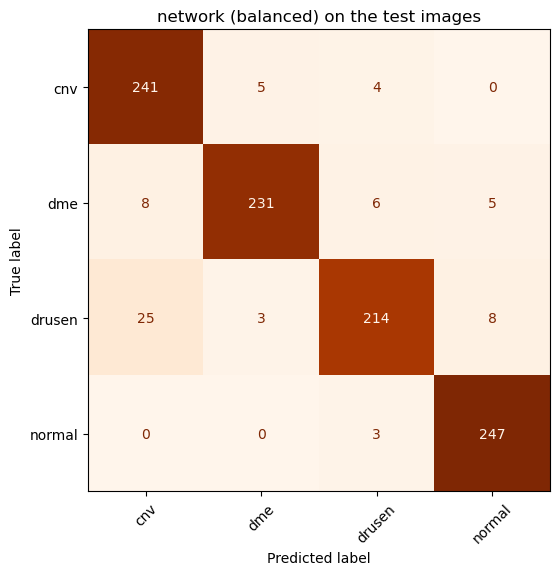

In [16]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def prep(x):
    t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    return (F.interpolate(t, size=(224, 224), mode="bilinear") - MEAN) / STD
net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).eval().to(device)
body = nn.Sequential(*list(net.children())[:-1])              # everything except the last layer
with torch.no_grad():
    FEAT = {s: torch.cat([body(prep(X[s][i:i + 128]).to(device)).flatten(1).cpu() for i in range(0, len(X[s]), 128)]) for s in X}

def train_head(seed=0, balanced=False, epochs=10):
    torch.manual_seed(seed)
    head = nn.Linear(512, len(CLASSES)); opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    w = torch.tensor(len(Y["train"]) / (len(CLASSES) * np.maximum(counts["train"], 1)), dtype=torch.float32) if balanced else None
    x, y = FEAT["train"], torch.tensor(Y["train"]).long()
    for _ in range(epochs):
        o = torch.randperm(len(y))
        for i in range(0, len(o), 64):
            b = o[i:i + 64]; loss = F.cross_entropy(head(x[b]), y[b], weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
    return head.eval()
def probs(head, s="test"):
    with torch.no_grad(): return F.softmax(head(FEAT[s]), 1).numpy()

heads = {"plain": train_head(0), "balanced": train_head(0, balanced=True)}
for k, h in heads.items():
    a, f = score(probs(h).argmax(1)); print(f"network, {k:8s}: accuracy {a:.1%}, {CLASSES[F_]} found {f:.1%}")
USE = "balanced"      # the version used from here on (change to "plain" if that answers your question better)
head = heads[USE]; P_test = probs(head); pred = P_test.argmax(1); acc, focus = score(pred)
fig, ax = plt.subplots(figsize=(1.0 * len(CLASSES) + 3, 1.0 * len(CLASSES) + 2))
ConfusionMatrixDisplay(confusion_matrix(Y["test"], pred), display_labels=[c[:14] for c in CLASSES]).plot(ax=ax, cmap="Oranges", colorbar=False, xticks_rotation=45)
ax.set_title(f"network ({USE}) on the test images"); fig.savefig(R / "confusion_cnv.png", dpi=150, bbox_inches="tight"); plt.show()

In [17]:
numbers = f"""| model | accuracy | {CLASSES[F_]} found |
|---|---|---|
| floor: always '{CLASSES[majority]}' | {floor:.1%} | {floor_focus:.0%} |
| random forest on colour features | {acc_rf:.1%} | {focus_rf:.1%} |
| ResNet-18 frozen, plain | {score(probs(heads['plain']).argmax(1))[0]:.1%} | {score(probs(heads['plain']).argmax(1))[1]:.1%} |
| ResNet-18 frozen, balanced | {score(probs(heads['balanced']).argmax(1))[0]:.1%} | {score(probs(heads['balanced']).argmax(1))[1]:.1%} |
"""
(R / "numbers_cnv.md").write_text(numbers); print(numbers)

| model | accuracy | cnv found |
|---|---|---|
| floor: always 'cnv' | 25.0% | 100% |
| random forest on colour features | 58.9% | 98.4% |
| ResNet-18 frozen, plain | 88.2% | 99.2% |
| ResNet-18 frozen, balanced | 93.3% | 96.4% |



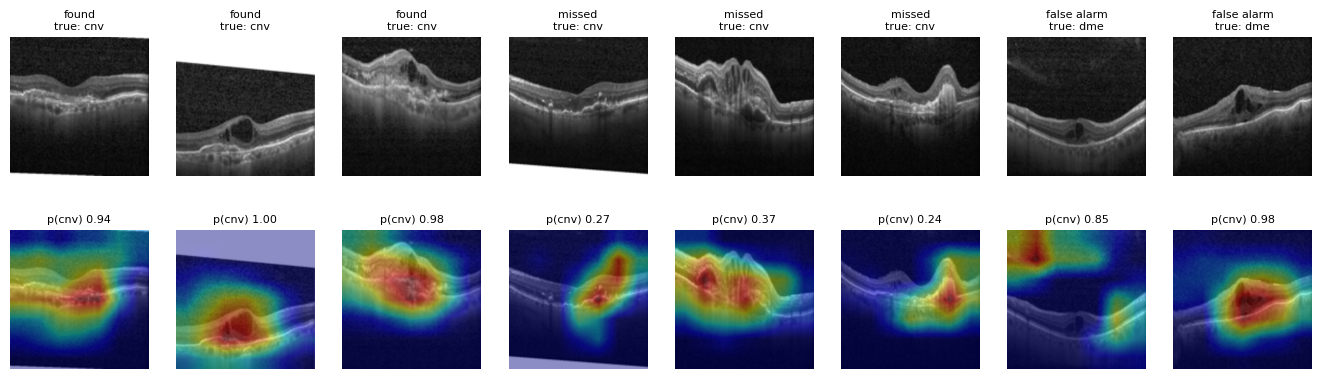

In [18]:
full = nn.Sequential(body, nn.Flatten(), copy.deepcopy(head).to(device)).eval()
def gradcam(model, x, cls):
    acts = {}
    h = model[0][7].register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))      # model[0][7] = layer4, the last conv block
    x = x.to(device).requires_grad_(True); out = model(x)
    g = torch.autograd.grad(out[range(len(cls)), cls].sum(), acts["a"])[0]; h.remove()
    cam = F.relu((g.mean((2, 3), keepdim=True) * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[:, 0]
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).detach().cpu().numpy()
y = Y["test"]
groups = {"found": np.where((y == F_) & (pred == F_))[0][:3], "missed": np.where((y == F_) & (pred != F_))[0][:3],
          "false alarm": np.where((y != F_) & (pred == F_))[0][:2]}
show = [(g, i) for g, idx in groups.items() for i in idx]
cams = gradcam(full, prep(X["test"][[i for _, i in show]]), torch.full((len(show),), F_))
fig, axes = plt.subplots(2, len(show), figsize=(2.1 * len(show), 4.6), squeeze=False)
for k, ((g, i), c) in enumerate(zip(show, cams)):
    big = np.asarray(Image.fromarray(X["test"][i]).resize((224, 224)))
    axes[0, k].imshow(big); axes[0, k].set_title(f"{g}\ntrue: {CLASSES[y[i]][:12]}", fontsize=8)
    axes[1, k].imshow(big); axes[1, k].imshow(c, cmap="jet", alpha=0.45); axes[1, k].set_title(f"p({CLASSES[F_][:10]}) {P_test[i, F_]:.2f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
fig.savefig(R / "gradcam_cnv.png", dpi=150, bbox_inches="tight"); plt.show()

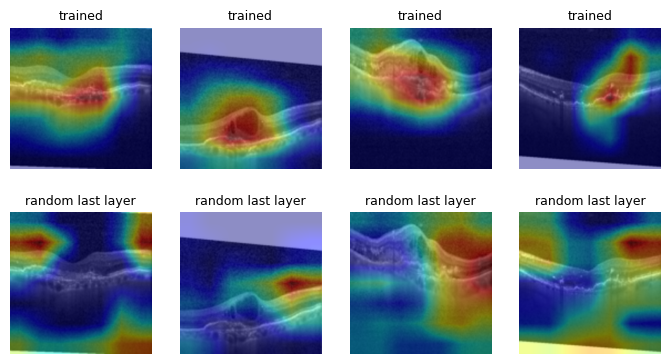

similarity trained vs random maps (correlation, 1 = identical): -0.37 0.17 -0.27 0.32 -0.69 -0.25 -0.12 -0.32


In [19]:
torch.manual_seed(1); rand_head = nn.Linear(512, len(CLASSES))
rand_full = nn.Sequential(body, nn.Flatten(), rand_head.to(device)).eval()
cams_r = gradcam(rand_full, prep(X["test"][[i for _, i in show]]), torch.full((len(show),), F_))
same = [float(np.corrcoef(a.ravel(), b.ravel())[0, 1]) if a.std() > 0 and b.std() > 0 else float("nan") for a, b in zip(cams, cams_r)]
fig, axes = plt.subplots(2, 4, figsize=(8.4, 4.4))
for k in range(4):
    big = np.asarray(Image.fromarray(X["test"][show[k][1]]).resize((224, 224)))
    for r, (c, t) in enumerate([(cams[k], "trained"), (cams_r[k], "random last layer")]):
        axes[r, k].imshow(big); axes[r, k].imshow(c, cmap="jet", alpha=0.45); axes[r, k].set_title(t, fontsize=9); axes[r, k].axis("off")
fig.savefig(R / "sanity_cnv.png", dpi=150, bbox_inches="tight"); plt.show()
print("similarity trained vs random maps (correlation, 1 = identical):", " ".join(f"{s:.2f}" for s in same))

In [20]:
seed_res = [score(probs(train_head(s, balanced=(USE == "balanced"))).argmax(1)) for s in (0, 1, 2)]
sa, sf = np.array(seed_res).T
print(f"accuracy {sa.mean():.1%} ± {sa.std(ddof=1):.1%}   {CLASSES[F_]} found {sf.mean():.1%} ± {sf.std(ddof=1):.1%}   (3 seeds)")
(R / "seeds_cnv.json").write_text(json.dumps({"accuracy": sa.tolist(), "focus_found": sf.tolist()}))

accuracy 93.2% ± 0.1%   cnv found 95.3% ± 1.0%   (3 seeds)


73

accuracy 93.3%  (95 % interval 91.7% to 94.8%)
cnv found 241 of 250 = 96.4%  (95 % interval 93.9% to 98.5%)


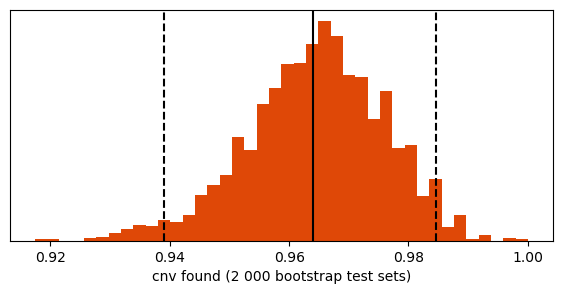

In [21]:
rng = np.random.default_rng(0); B = 2000; n = len(y); boot_acc, boot_f = [], []
for _ in range(B):
    i = rng.integers(0, n, n); boot_acc.append(np.mean(pred[i] == y[i])); m = y[i] == F_; boot_f.append(np.mean(pred[i][m] == F_))
ci_acc, ci_f = np.percentile(boot_acc, [2.5, 97.5]), np.percentile(boot_f, [2.5, 97.5])
n_f = int((y == F_).sum()); k_f = int(((y == F_) & (pred == F_)).sum())
print(f"accuracy {acc:.1%}  (95 % interval {ci_acc[0]:.1%} to {ci_acc[1]:.1%})")
print(f"{CLASSES[F_]} found {k_f} of {n_f} = {focus:.1%}  (95 % interval {ci_f[0]:.1%} to {ci_f[1]:.1%})")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(boot_f, bins=40, color="#DF4807"); ax.axvline(focus, color="k")
for v in ci_f: ax.axvline(v, color="k", ls="--")
ax.set_xlabel(f"{CLASSES[F_]} found (2 000 bootstrap test sets)"); ax.set_yticks([])
fig.savefig(R / "bootstrap_cnv.png", dpi=150, bbox_inches="tight"); plt.show()

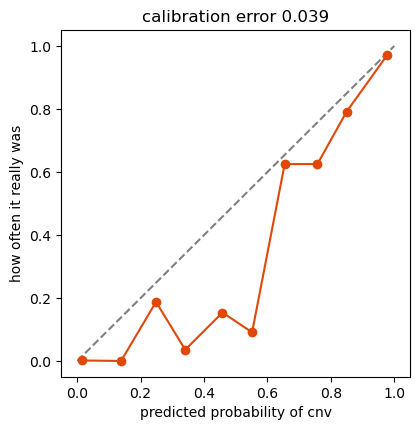

calibration error (ECE) for 'cnv': 0.039   (0 = the probabilities can be taken at their word)


In [22]:
p = P_test[:, F_]; truth = (y == F_).astype(float); bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
mean_p = np.array([p[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)])
frac = np.array([truth[idx == b].mean() if (idx == b).any() else np.nan for b in range(10)])
nb = np.array([(idx == b).sum() for b in range(10)])
ece = float(np.nansum(nb * np.abs(mean_p - frac)) / n)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.plot(mean_p, frac, "o-", color="#DF4807")
ax.set_xlabel(f"predicted probability of {CLASSES[F_]}"); ax.set_ylabel("how often it really was"); ax.set_title(f"calibration error {ece:.3f}")
fig.savefig(R / "calibration_cnv.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"calibration error (ECE) for '{CLASSES[F_]}': {ece:.3f}   (0 = the probabilities can be taken at their word)")

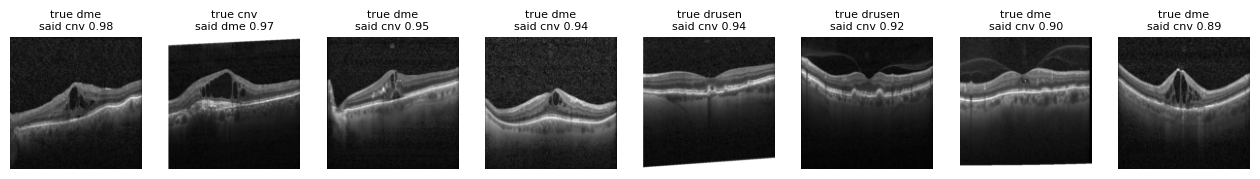

In [23]:
wrong = np.where(pred != y)[0]; worst = wrong[np.argsort(-P_test[wrong, pred[wrong]])][:8]
fig, axes = plt.subplots(1, len(worst), figsize=(2 * len(worst), 2.6), squeeze=False)
for a, i in zip(axes[0], worst):
    a.imshow(X["test"][i]); a.set_title(f"true {CLASSES[y[i]][:11]}\nsaid {CLASSES[pred[i]][:11]} {P_test[i, pred[i]]:.2f}", fontsize=8); a.axis("off")
fig.savefig(R / "worst_cnv.png", dpi=150, bbox_inches="tight"); plt.show()

In [26]:
summary = f"""Question: {QUESTION}
On {n} test images, the frozen ResNet-18 ({USE}) found {k_f} of {n_f} {CLASSES[F_]} images ({focus:.1%}; 95 % bootstrap interval {ci_f[0]:.1%} to {ci_f[1]:.1%}).
Accuracy {acc:.1%} (interval {ci_acc[0]:.1%} to {ci_acc[1]:.1%}); floor {floor:.1%}; random-forest baseline {acc_rf:.1%}.
Three training seeds: {CLASSES[F_]} found {sf.mean():.1%} ± {sf.std(ddof=1):.1%}. Calibration error for {CLASSES[F_]}: {ece:.3f}.
Limits: one data set, test images from the same source (internal validation only); {len(twins)} near-twins between training and test; {patient_line}.
"""
(R / "summary_dme.md").write_text(summary); print(summary)
import sklearn, torchvision
Path("requirements.txt").write_text(f"numpy=={np.__version__}\ntorch=={torch.__version__.split('+')[0]}\ntorchvision=={torchvision.__version__.split('+')[0]}\n"
                                    f"scikit-learn=={sklearn.__version__}\nmatplotlib\nPillow\nrequests\n")
print(Path("requirements.txt").read_text())
print("README · How to run: open the notebook in Google Colab (T4 GPU), set the YOUR DATA cell, Runtime → Run all (about 3 minutes).")

Question: Can a neural network, pre-trained on ImageNet images, identify choroidal neovascularisation and diabetic macular edema to classify the patients as 'urgent referrals'?
On 1000 test images, the frozen ResNet-18 (balanced) found 241 of 250 cnv images (96.4%; 95 % bootstrap interval 93.9% to 98.5%).
Accuracy 93.3% (interval 91.7% to 94.8%); floor 25.0%; random-forest baseline 58.9%.
Three training seeds: cnv found 95.3% ± 1.0%. Calibration error for cnv: 0.039.
Limits: one data set, test images from the same source (internal validation only); 697 near-twins between training and test; 4416 training / 633 test patients; 561 in both.

numpy==2.3.5
torch==2.15.0
torchvision==0.29.2
scikit-learn==1.8.0
matplotlib
Pillow
requests

README · How to run: open the notebook in Google Colab (T4 GPU), set the YOUR DATA cell, Runtime → Run all (about 3 minutes).


In [25]:
with zipfile.ZipFile("results_cnv.zip", "w") as z:
    for f in sorted(R.iterdir()): z.write(f)
    z.write("requirements.txt")
try:
    from google.colab import files; files.download("results.zip")
except ImportError:
    print("results_cnv.zip written:", sorted(f.name for f in R.iterdir()))

results_cnv.zip written: ['bootstrap_cnv.png', 'calibration_cnv.png', 'confusion_cnv.png', 'counts_cnv.csv', 'data_table_cnv.md', 'examples_cnv.png', 'gradcam_cnv.png', 'numbers_cnv.md', 'sanity_cnv.png', 'seeds_cnv.json', 'summary_cnv.md', 'twins_cnv.png', 'worst_cnv.png']
